<a href="https://colab.research.google.com/github/ashirshaukat15-ai/SER-Baseline-Reproduction/blob/main/SER_Baseline_Reproduction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Cell 1: Install dependencies and download dataset
!pip install librosa==0.10.1 tensorflow scikit-learn==1.3.0 seaborn==0.12.2

# Download RAVDESS dataset directly into the Colab environment
import os
!kaggle datasets download -d uwrfkaggler/ravdess-emotional-speech-audio
!unzip -q ravdess-emotional-speech-audio.zip -d audio_speech_actors_01-24
print("Dataset downloaded and extracted.")

  Using cached librosa-0.10.1-py3-none-any.whl.metadata (8.3 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 92.4 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  error: subprocess-exited-with-error
  
  × Preparing metadata (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Preparing metadata (pyproject.toml) ... error
error: metadata-generation-failed

× Encountered error while generating package metadata.
╰─> scikit-learn

note: This is an issue with the package mentioned above, not pip.
hint: See above for details.
Dataset URL: https://www.kaggle.com/datasets/uwrfkaggler/ravdess-emotional-speech-audio
License(s): CC-BY-NC-SA-4.0
ravdess-emotional-speech-audio.zip: Skipping, found more recently modified local copy (use --force to force download)
replace audio_speech_actors_01-24/Actor_01/03

In [3]:
# Cell 1: Install dependencies and download dataset
# We remove strict versioning for scikit-learn and librosa to avoid Colab/Python 3.12 errors.
!pip install librosa tensorflow scikit-learn seaborn

import os

# Download RAVDESS dataset directly into the Colab environment
!kaggle datasets download -d uwrfkaggler/ravdess-emotional-speech-audio

# Unzip and organize
!unzip -q ravdess-emotional-speech-audio.zip
!mkdir -p audio_speech_actors_01-24
# Move all Actor folders into the target directory
!mv Actor_* audio_speech_actors_01-24/

print("Environment setup complete. Dataset downloaded and extracted.")

Dataset URL: https://www.kaggle.com/datasets/uwrfkaggler/ravdess-emotional-speech-audio
License(s): CC-BY-NC-SA-4.0
ravdess-emotional-speech-audio.zip: Skipping, found more recently modified local copy (use --force to force download)
replace audio_speech_actors_01-24/Actor_01/03-01-01-01-01-01-01.wav? [y]es, [n]o, [A]ll, [N]one, [r]ename: A
mv: cannot overwrite 'audio_speech_actors_01-24/Actor_01': Directory not empty
mv: cannot overwrite 'audio_speech_actors_01-24/Actor_02': Directory not empty
mv: cannot overwrite 'audio_speech_actors_01-24/Actor_03': Directory not empty
mv: cannot overwrite 'audio_speech_actors_01-24/Actor_04': Directory not empty
mv: cannot overwrite 'audio_speech_actors_01-24/Actor_05': Directory not empty
mv: cannot overwrite 'audio_speech_actors_01-24/Actor_06': Directory not empty
mv: cannot overwrite 'audio_speech_actors_01-24/Actor_07': Directory not empty
mv: cannot overwrite 'audio_speech_actors_01-24/Actor_08': Directory not empty
mv: cannot overwrite 'aud

In [4]:
import os

data_path = './audio_speech_actors_01-24/'
if os.path.exists(data_path):
    actors = os.listdir(data_path)
    print(f"Found {len(actors)} actor folders.")
    first_actor = os.path.join(data_path, actors[0])
    files = os.listdir(first_actor)
    print(f"First actor has {len(files)} files. Example: {files[0]}")
else:
    print("ERROR: Folder not found. Please check the unzip step.")

Found 25 actor folders.
First actor has 60 files. Example: 03-01-01-01-02-02-03.wav


In [5]:
import numpy as np
import librosa
import time

# Define paths
data_path = './audio_speech_actors_01-24/'
emotions = {
    '01': 'neutral', '02': 'calm', '03': 'happy', '04': 'sad',
    '05': 'angry', '06': 'fearful', '07': 'disgust', '08': 'surprised'
}
emotion_labels = list(emotions.values())

def extract_features(file_path):
    # Load audio (resample to 22050 Hz as per paper)
    y, sr = librosa.load(file_path, sr=22050)

    # Extract features
    zcr = np.mean(librosa.feature.zero_crossing_rate(y))
    rmse = np.mean(librosa.feature.rms(y=y))
    chroma = np.mean(librosa.feature.chroma_stft(y=y, sr=sr), axis=1)
    mfcc = np.mean(librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20), axis=1)

    # Concatenate
    return np.concatenate(([zcr, rmse], chroma, mfcc))

print("Starting feature extraction...")
start_time = time.time()

X = []
y = []

for actor_folder in os.listdir(data_path):
    actor_path = os.path.join(data_path, actor_folder)
    # Skip hidden system folders and ensure it's a directory
    if not os.path.isdir(actor_path) or actor_folder.startswith('.'):
        continue

    for file in os.listdir(actor_path):
        if file.endswith('.wav'):
            file_path = os.path.join(actor_path, file)

            # Extract emotion from filename (3rd part of the filename)
            emotion_code = file.split('-')[2]
            if emotion_code in emotions:
                label = emotion_labels.index(emotions[emotion_code])

                # Extract features
                features = extract_features(file_path)
                X.append(features)
                y.append(label)

X = np.array(X)
y = np.array(y)

print(f"Extraction complete! Time taken: {time.time() - start_time:.2f} seconds")
print(f"Feature matrix shape: {X.shape}")
print(f"Labels shape: {y.shape}")

Starting feature extraction...
Extraction complete! Time taken: 82.87 seconds
Feature matrix shape: (1440, 34)
Labels shape: (1440,)


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.utils import to_categorical

print("Preparing and scaling data...")

# 1. Split into Train+Val (90%) and Test (10%)
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.10, random_state=42, stratify=y
)

# 2. Split Train+Val into Train (80% of total) and Val (10% of total)
# 0.111 of 90% is approximately 10% of the total dataset
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.111, random_state=42, stratify=y_train_val
)

# 3. Standard Scaling (Fit ONLY on training data to prevent data leakage)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

# 4. Reshape for 1D CNN (Samples, Features, 1 Channel)
X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_val = X_val.reshape(X_val.shape[0], X_val.shape[1], 1)
X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

# 5. One-hot encode labels for categorical cross-entropy
y_train_cat = to_categorical(y_train, num_classes=8)
y_val_cat = to_categorical(y_val, num_classes=8)
y_test_cat = to_categorical(y_test, num_classes=8)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Validation set: {X_val.shape[0]} samples")
print(f"Testing set: {X_test.shape[0]} samples")

Preparing and scaling data...
Training set: 1152 samples
Validation set: 144 samples
Testing set: 144 samples


In [7]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, BatchNormalization, Dropout, Flatten, Dense, Bidirectional, LSTM
import matplotlib.pyplot as plt

# 1. Define 1D CNN
def build_1d_cnn(input_shape):
    model = Sequential([
        Conv1D(64, 5, strides=1, padding='same', activation='relu', input_shape=input_shape),
        BatchNormalization(), MaxPooling1D(2),
        Conv1D(128, 5, strides=1, padding='same', activation='relu'),
        BatchNormalization(), MaxPooling1D(2), Dropout(0.3),
        Conv1D(256, 5, strides=1, padding='same', activation='relu'),
        BatchNormalization(), MaxPooling1D(2),
        Conv1D(256, 3, strides=1, padding='same', activation='relu'),
        BatchNormalization(), MaxPooling1D(2), Dropout(0.3),
        Conv1D(128, 3, strides=1, padding='same', activation='relu'),
        BatchNormalization(), MaxPooling1D(2), Dropout(0.3),
        Flatten(),
        Dense(256, activation='relu'),
        BatchNormalization(),
        Dense(8, activation='softmax')
    ])
    return model

# 2. Define CNN-BiLSTM
def build_cnn_bilstm(input_shape):
    model = Sequential([
        Conv1D(64, 5, strides=1, padding='same', activation='relu', input_shape=input_shape),
        BatchNormalization(), MaxPooling1D(2),
        Conv1D(128, 5, strides=1, padding='same', activation='relu'),
        BatchNormalization(), MaxPooling1D(2), Dropout(0.3),
        Conv1D(256, 5, strides=1, padding='same', activation='relu'),
        BatchNormalization(), MaxPooling1D(2),
        Conv1D(256, 3, strides=1, padding='same', activation='relu'),
        BatchNormalization(), MaxPooling1D(2), Dropout(0.3),
        Conv1D(128, 3, strides=1, padding='same', activation='relu'),
        BatchNormalization(), MaxPooling1D(2), Dropout(0.3),
        Bidirectional(LSTM(128)),
        Dense(256, activation='relu'),
        Dense(8, activation='softmax')
    ])
    return model

input_shape = (X_train.shape[1], 1)

# Early stopping to prevent overfitting
early_stop = tf.keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)

# Compile and Train Model 1 (CNN)
print("--- Training 1D CNN ---")
model_cnn = build_1d_cnn(input_shape)
model_cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
history_cnn = model_cnn.fit(X_train, y_train_cat, validation_data=(X_val, y_val_cat),
                            epochs=100, batch_size=64, callbacks=[early_stop], verbose=1)

# Compile and Train Model 2 (CNN-BiLSTM)
print("\n--- Training CNN-BiLSTM ---")
model_bilstm = build_cnn_bilstm(input_shape)
model_bilstm.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
history_bilstm = model_bilstm.fit(X_train, y_train_cat, validation_data=(X_val, y_val_cat),
                                  epochs=100, batch_size=64, callbacks=[early_stop], verbose=1)

--- Training 1D CNN ---


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 8s 157ms/step - accuracy: 0.1780 - loss: 2.4081 - val_accuracy: 0.1597 - val_loss: 2.0624
Epoch 2/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 125ms/step - accuracy: 0.2691 - loss: 2.0232 - val_accuracy: 0.1389 - val_loss: 2.0816
Epoch 3/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 85ms/step - accuracy: 0.2917 - loss: 1.9436 - val_accuracy: 0.1389 - val_loss: 2.1036
Epoch 4/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 85ms/step - accuracy: 0.3316 - loss: 1.7899 - val_accuracy: 0.1389 - val_loss: 2.1378
Epoch 5/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 85ms/step - accuracy: 0.3845 - loss: 1.6917 - val_accuracy: 0.1389 - val_loss: 2.1773
Epoch 6/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 86ms/step - accuracy: 0.4132 - loss: 1.5586 - val_accuracy: 0.1319 - val_loss: 2.2422
Epoch 7/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 135ms/step - accuracy: 0.4323 - loss: 1.5188 - val_accuracy: 0.1806 - val_loss: 2.2268
Epoch 8/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 123ms/step - accuracy: 0.4818 - loss: 1.3950 - val_accuracy

In [8]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, BatchNormalization, Dropout, Flatten, Dense, Bidirectional, LSTM, GlobalAveragePooling1D
import matplotlib.pyplot as plt
from tensorflow.keras.optimizers import Adam

# 1. ADAPTED 1D CNN (Reduced pooling to preserve the 34 features)
def build_1d_cnn_adapted(input_shape):
    model = Sequential([
        Conv1D(64, 3, strides=1, padding='same', activation='relu', input_shape=input_shape),
        BatchNormalization(),
        MaxPooling1D(2), # Length goes from 34 -> 17

        Conv1D(128, 3, strides=1, padding='same', activation='relu'),
        BatchNormalization(),
        MaxPooling1D(2), # Length goes from 17 -> 8
        Dropout(0.3),

        Conv1D(256, 3, strides=1, padding='same', activation='relu'),
        BatchNormalization(),
        # REMOVED 3rd and 4th MaxPooling layer to prevent data loss

        Flatten(),
        Dense(128, activation='relu'),
        Dropout(0.4), # Added dropout here to prevent overfitting
        Dense(8, activation='softmax')
    ])
    return model

# 2. ADAPTED CNN-BiLSTM
def build_cnn_bilstm_adapted(input_shape):
    model = Sequential([
        Conv1D(64, 3, strides=1, padding='same', activation='relu', input_shape=input_shape),
        BatchNormalization(),
        MaxPooling1D(2),

        Conv1D(128, 3, strides=1, padding='same', activation='relu'),
        BatchNormalization(),
        MaxPooling1D(2),
        Dropout(0.3),

        Conv1D(256, 3, strides=1, padding='same', activation='relu'),
        BatchNormalization(),

        Bidirectional(LSTM(64)), # Reduced LSTM units
        Dropout(0.4),
        Dense(8, activation='softmax')
    ])
    return model

input_shape = (X_train.shape[1], 1)

# Use a lower learning rate to help the model converge better
optimizer = Adam(learning_rate=0.0005)

early_stop = tf.keras.callbacks.EarlyStopping(patience=15, restore_best_weights=True)

# --- Train Model 1 (CNN) ---
print("--- Training Adapted 1D CNN ---")
model_cnn = build_1d_cnn_adapted(input_shape)
model_cnn.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])

history_cnn = model_cnn.fit(X_train, y_train_cat, validation_data=(X_val, y_val_cat),
                            epochs=80, batch_size=32, callbacks=[early_stop], verbose=1)

# --- Train Model 2 (CNN-BiLSTM) ---
print("\n--- Training Adapted CNN-BiLSTM ---")
model_bilstm = build_cnn_bilstm_adapted(input_shape)
model_bilstm.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])

history_bilstm = model_bilstm.fit(X_train, y_train_cat, validation_data=(X_val, y_val_cat),
                                  epochs=80, batch_size=32, callbacks=[early_stop], verbose=1)

--- Training Adapted 1D CNN ---
Epoch 1/80
36/36 ━━━━━━━━━━━━━━━━━━━━ 8s 29ms/step - accuracy: 0.2674 - loss: 2.3505 - val_accuracy: 0.1875 - val_loss: 2.0481
Epoch 2/80
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.4149 - loss: 1.6481 - val_accuracy: 0.1736 - val_loss: 2.0601
Epoch 3/80
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.4774 - loss: 1.4257 - val_accuracy: 0.1597 - val_loss: 2.1182
Epoch 4/80
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.5130 - loss: 1.2660 - val_accuracy: 0.3125 - val_loss: 2.0981
Epoch 5/80
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.5747 - loss: 1.1679 - val_accuracy: 0.2083 - val_loss: 2.2077
Epoch 6/80
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.6094 - loss: 1.0598 - val_accuracy: 0.2847 - val_loss: 1.9971
Epoch 7/80
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.6597 - loss: 0.9506 - val_accuracy: 0.2708 - val_loss: 2.0007
Epoch 8/80
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.6806 - loss: 0

ValueError: Unknown variable: <Variable path=sequential_3/conv1d_13/kernel, shape=(3, 1, 64), dtype=float32>. This optimizer can only be called for the variables it was originally built with. When working with a new set of variables, you should recreate a new optimizer instance.

In [9]:
from tensorflow.keras.optimizers import Adam

print("--- Training Adapted CNN-BiLSTM ---")
model_bilstm = build_cnn_bilstm_adapted(input_shape)

# Create a FRESH optimizer instance here
model_bilstm.compile(optimizer=Adam(learning_rate=0.0005),
                     loss='categorical_crossentropy',
                     metrics=['accuracy'])

history_bilstm = model_bilstm.fit(X_train, y_train_cat, validation_data=(X_val, y_val_cat),
                                  epochs=80, batch_size=32, callbacks=[early_stop], verbose=1)

--- Training Adapted CNN-BiLSTM ---
Epoch 1/80
36/36 ━━━━━━━━━━━━━━━━━━━━ 21s 83ms/step - accuracy: 0.1997 - loss: 2.0391 - val_accuracy: 0.1944 - val_loss: 2.0946
Epoch 2/80
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.3255 - loss: 1.8095 - val_accuracy: 0.1319 - val_loss: 2.1816
Epoch 3/80
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.3689 - loss: 1.7136 - val_accuracy: 0.1319 - val_loss: 2.2616
Epoch 4/80
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 60ms/step - accuracy: 0.4115 - loss: 1.5994 - val_accuracy: 0.1319 - val_loss: 2.2313
Epoch 5/80
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 54ms/step - accuracy: 0.4566 - loss: 1.5194 - val_accuracy: 0.1528 - val_loss: 2.2426
Epoch 6/80
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - accuracy: 0.4965 - loss: 1.4309 - val_accuracy: 0.1875 - val_loss: 2.2282
Epoch 7/80
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.5234 - loss: 1.3617 - val_accuracy: 0.1875 - val_loss: 2.2860
Epoch 8/80
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.5747 - lo

Evaluating Ensemble...
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 73ms/step
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 169ms/step

=== REPRODUCED RESULTS ===
Ensemble Accuracy: 64.58%
Ensemble Macro F1-Score: 0.6223
Ensemble AUC-ROC: 0.9273

Saved 'training_curves.png' to Colab files!
Saved 'confusion_matrix.png' to Colab files!


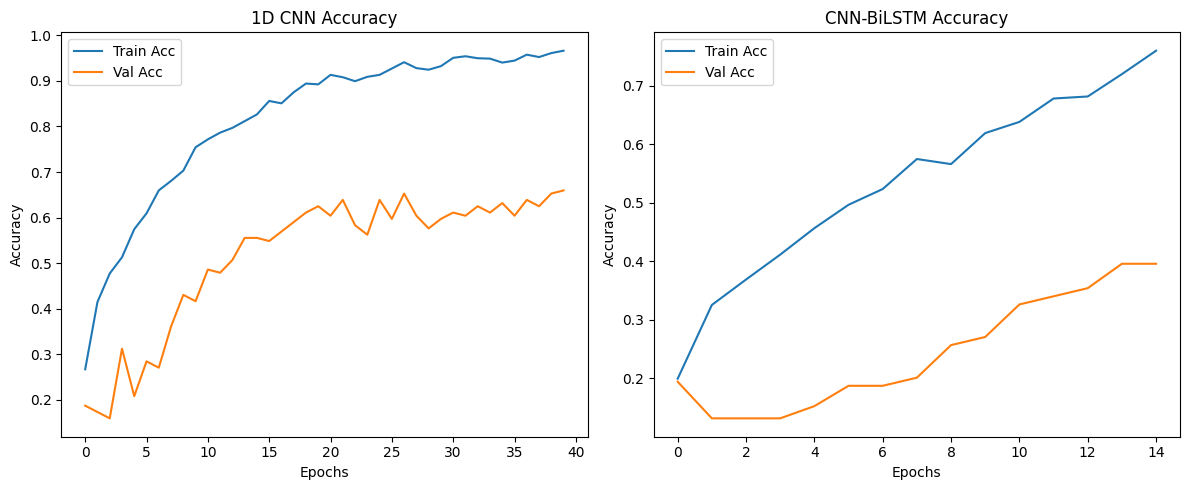

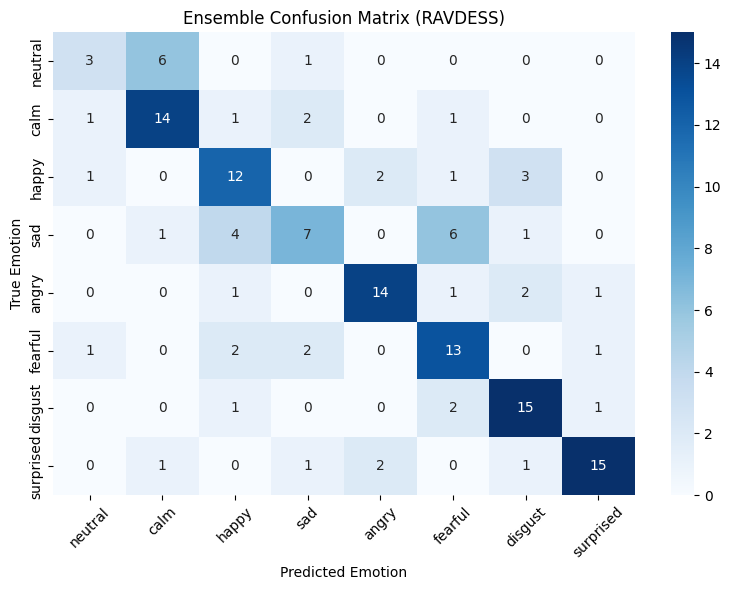

In [10]:
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Ensemble Prediction (Probability Averaging)
print("Evaluating Ensemble...")
pred_cnn = model_cnn.predict(X_test)
pred_bilstm = model_bilstm.predict(X_test)

# Average the probabilities
pred_ensemble = (pred_cnn + pred_bilstm) / 2.0

# Get final class predictions
y_pred_ensemble = np.argmax(pred_ensemble, axis=1)

# 2. Calculate Metrics
acc = accuracy_score(y_test, y_pred_ensemble)
f1 = f1_score(y_test, y_pred_ensemble, average='macro')
auc = roc_auc_score(y_test_cat, pred_ensemble, multi_class='ovr', average='macro')

print("\n=== REPRODUCED RESULTS ===")
print(f"Ensemble Accuracy: {acc * 100:.2f}%")
print(f"Ensemble Macro F1-Score: {f1:.4f}")
print(f"Ensemble AUC-ROC: {auc:.4f}")

# 3. Generate Training Curves Graph
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_cnn.history['accuracy'], label='Train Acc')
plt.plot(history_cnn.history['val_accuracy'], label='Val Acc')
plt.title('1D CNN Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_bilstm.history['accuracy'], label='Train Acc')
plt.plot(history_bilstm.history['val_accuracy'], label='Val Acc')
plt.title('CNN-BiLSTM Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.savefig('training_curves.png')
print("\nSaved 'training_curves.png' to Colab files!")

# 4. Generate Confusion Matrix Graph
cm = confusion_matrix(y_test, y_pred_ensemble)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=list(emotions.values()),
            yticklabels=list(emotions.values()))
plt.title('Ensemble Confusion Matrix (RAVDESS)')
plt.ylabel('True Emotion')
plt.xlabel('Predicted Emotion')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('confusion_matrix.png')
print("Saved 'confusion_matrix.png' to Colab files!")